# Taller Semana 9: Regresión e IA para analítica
**Análisis de Datos · Ingeniería de Sistemas · 2026-2**

Caso: una disquera decide, **antes del lanzamiento**, qué canciones reciben mayor inversión promocional.
Pregunta: ¿qué popularidad (0-100) alcanzará una canción? Es una variable continua, por lo tanto una tarea de **regresión**.

Estructura (mapa del notebook de la lámina 29):

| Fase | Sección |
|---|---|
| 1 | Exploración y calidad de los datos |
| 2 | Momento de la decisión, tabla de control y fuga |
| 3 | Línea base, modelado y registro comparativo |
| 4 | Métricas, diagnóstico por segmento |
| 5 | Importancia y conclusión de negocio |
| Auditoría | Lectura crítica de un resultado generado por IA |
| Cierre | Registro, modelo y ficha para el servicio |

El notebook se ejecuta desde la carpeta `semana_09` del repositorio y usa `../data/canciones.csv` a través de `src/variables.py`.

In [1]:
import sys, warnings
sys.path.append("..")
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.variables import cargar_canciones, COLUMNAS_ENTRADA, ANIO_CORTE

SEMILLA = 42
import re
es = lambda t: re.sub(r"(?<=\d)\.(?=\d)", ",", t)      # decimales con coma en textos
np.random.seed(SEMILLA)
Path("figuras").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 160, "display.max_columns", 30)

datos = cargar_canciones()          # ordenado por año de lanzamiento
OBJETIVO = "popularidad"
print(datos.shape)
datos.head()

(2000, 13)


,bailabilidad,energia,valencia,acustica,tempo,duracion_min,volumen_db,anio,colaboracion,genero,reproducciones_sem1,popularidad,es_hit
0,0.376,0.648,0.425,0.119,96.1,2.20,-4.0,1995,0,indie,426829,60.2,0
1,0.828,0.824,0.377,0.154,109.2,2.68,-6.5,1995,1,indie,534264,66.1,0
2,0.189,0.761,0.300,0.373,200.0,4.39,-12.2,1995,0,urbano,256039,46.3,0
3,0.845,0.559,0.759,0.084,149.3,2.43,-6.3,1995,0,pop,561896,67.9,0
4,0.429,0.893,0.419,0.441,134.3,5.23,-8.8,1995,0,electronica,459289,63.6,0


## Separar el pasado del futuro (la partición se define antes de explorar)

Si el modelo va a predecir canciones **futuras**, la prueba son las más recientes: se entrena con 1995-2019 y se prueba **una sola vez** con 2020-2025.
Toda la exploración se hace solo con entrenamiento, para no «mirar» la prueba.

In [2]:
m_ent = datos["anio"] < ANIO_CORTE
m_pru = ~m_ent
print(f"Entrenamiento: {m_ent.sum()} canciones ({datos.loc[m_ent,'anio'].min()}-{datos.loc[m_ent,'anio'].max()})")
print(f"Prueba:        {m_pru.sum()} canciones ({datos.loc[m_pru,'anio'].min()}-{datos.loc[m_pru,'anio'].max()})")

X_todo, y = datos.drop(columns=OBJETIVO), datos[OBJETIVO]
Xe, ye = X_todo[m_ent], y[m_ent]
Xp, yp = X_todo[m_pru], y[m_pru]
E = datos[m_ent]                    # solo entrenamiento para explorar

Entrenamiento: 1585 canciones (1995-2019)
Prueba:        415 canciones (2020-2025)


## Fase 1. Explorar sin mirar la prueba: exploración y calidad de los datos

In [3]:
print("Duplicados (dataset completo):", datos.duplicated().sum(), "| Nulos totales:", datos.isna().sum().sum())
calidad = pd.DataFrame({"tipo": E.dtypes.astype(str), "nulos": E.isna().sum(), "valores_unicos": E.nunique()})
display(calidad)
display(E.describe().T.round(2))
print(E["genero"].value_counts().to_string())

Duplicados (dataset completo): 0 | Nulos totales: 0


,tipo,nulos,valores_unicos
bailabilidad,float64,0,700
energia,float64,0,697
valencia,float64,0,742
acustica,float64,0,677
tempo,float64,0,776
duracion_min,float64,0,356
volumen_db,float64,0,157
anio,int64,0,25
colaboracion,int64,0,2
genero,object,0,5


,count,mean,std,min,25%,50%,75%,max
bailabilidad,1585.0,0.52,0.22,0.03,0.36,0.53,0.69,0.99
energia,1585.0,0.57,0.21,0.03,0.42,0.58,0.73,1.00
valencia,1585.0,0.49,0.23,0.02,0.32,0.50,0.68,0.96
acustica,1585.0,0.34,0.20,0.00,0.18,0.32,0.48,0.94
tempo,1585.0,119.99,24.80,60.00,103.20,119.10,135.70,200.00
duracion_min,1585.0,3.50,0.81,1.50,2.96,3.50,4.05,6.15
volumen_db,1585.0,-8.00,3.02,-18.80,-10.00,-8.00,-6.00,0.00
anio,1585.0,2007.30,7.20,1995.00,2001.00,2007.00,2014.00,2019.00
colaboracion,1585.0,0.25,0.43,0.00,0.00,0.00,1.00,1.00
reproducciones_sem1,1585.0,421317.52,178424.77,18475.00,289851.00,406438.00,537617.00,1121386.00


genero
pop            488
urbano         413
rock           266
electronica    220
indie          198


**Lectura.** No hay nulos ni duplicados, así que no hace falta imputar ni eliminar filas. Tipos coherentes: ocho numéricas continuas, `colaboracion` binaria, `genero` categórica (5 niveles) y `anio` entera.
Se revisan ahora los valores extremos con la regla del rango intercuartílico (IQR).

In [4]:
num_feat = [c for c in COLUMNAS_ENTRADA if c != "genero"]

def fuera_iqr(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

cols_rev = [c for c in num_feat if c not in ("colaboracion", "anio")] + [OBJETIVO, "reproducciones_sem1"]
atip = pd.DataFrame({c: fuera_iqr(E[c]) for c in cols_rev})
resumen = pd.DataFrame({"n_atipicos": atip.sum(), "%": (atip.mean() * 100).round(1),
                        "minimo": E[cols_rev].min(), "maximo": E[cols_rev].max()})
display(resumen)

,n_atipicos,%,minimo,maximo
bailabilidad,0,0.0,0.030,0.994
energia,0,0.0,0.030,0.995
valencia,0,0.0,0.016,0.961
acustica,1,0.1,0.001,0.943
tempo,8,0.5,60.000,200.000
duracion_min,7,0.4,1.500,6.150
volumen_db,5,0.3,-18.800,0.000
popularidad,10,0.6,11.600,100.000
reproducciones_sem1,10,0.6,18475.000,1121386.000


**Decisión sobre los extremos.** Son pocos (menos del 2 % por columna) y plausibles: tempo entre 60 y 200 bpm, volumen hasta 0 dB (máximo físico), duración entre 1,5 y 6 minutos y popularidad dentro de 0-100.
No son errores de captura, así que **no se eliminan**. Para comprobar que la decisión no afecta el resultado, se mide la sensibilidad más abajo (sección de modelado): se reajusta el modelo sin las filas con algún extremo y se compara el error en prueba.

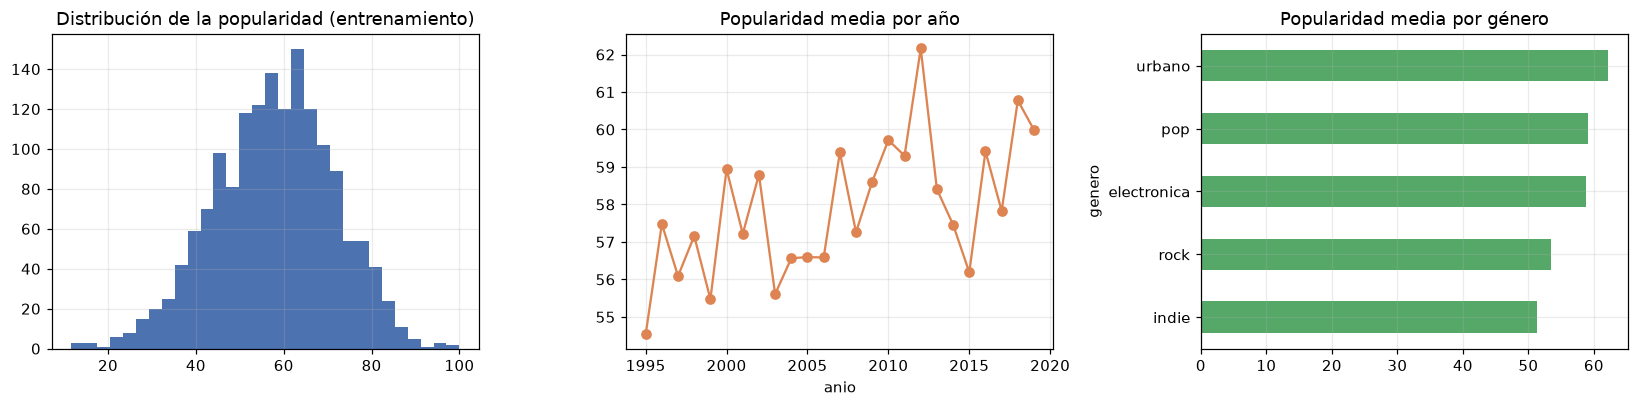

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(E[OBJETIVO], bins=30, color="#4C72B0"); ax[0].set_title("Distribución de la popularidad (entrenamiento)")
E.groupby("anio")[OBJETIVO].mean().plot(ax=ax[1], marker="o", color="#DD8452"); ax[1].set_title("Popularidad media por año")
E.groupby("genero")[OBJETIVO].mean().sort_values().plot.barh(ax=ax[2], color="#55A868"); ax[2].set_title("Popularidad media por género")
plt.tight_layout(); plt.savefig("figuras/f1_exploracion.png"); plt.show()

,reproducciones_sem1,es_hit,bailabilidad,energia,colaboracion,valencia,volumen_db,anio,tempo,duracion_min,acustica
correlación con popularidad,0.99,0.67,0.52,0.43,0.2,0.19,0.13,0.08,-0.0,-0.05,-0.2


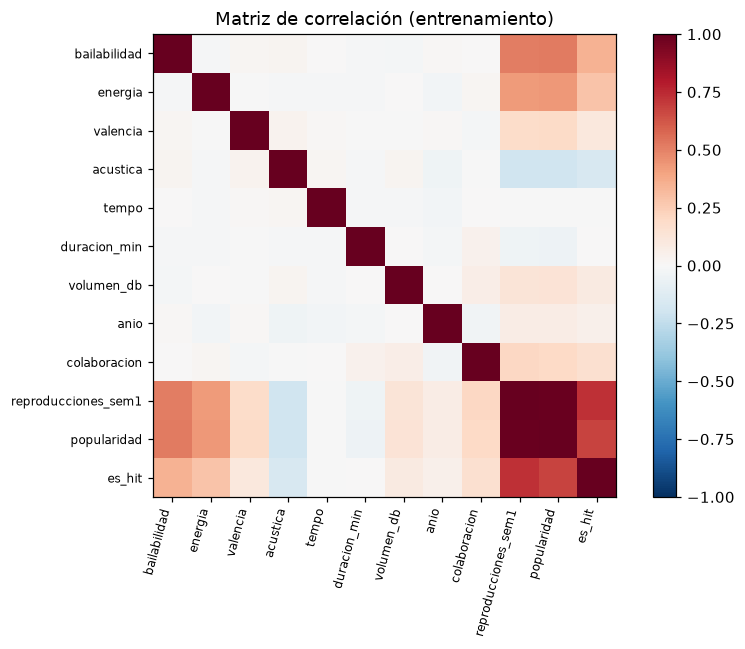

Mayor correlación entre explicativas: ('volumen_db', 'colaboracion') 0.063


VIF: {'bailabilidad': 1.0, 'energia': 1.0, 'valencia': 1.0, 'acustica': 1.01, 'tempo': 1.0, 'duracion_min': 1.0, 'volumen_db': 1.01, 'anio': 1.01, 'colaboracion': 1.01}


In [6]:
corr = E.drop(columns="genero").corr()
display(corr[OBJETIVO].drop(OBJETIVO).sort_values(ascending=False).round(2).to_frame("correlación con popularidad").T)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8); ax.grid(False)
plt.colorbar(im); ax.set_title("Matriz de correlación (entrenamiento)")
plt.tight_layout(); plt.savefig("figuras/f2_correlaciones.png"); plt.show()

# Redundancia entre variables explicativas: correlación máxima entre pares y factor de inflación de la varianza (VIF)
Z = E[num_feat]
pares = corr.loc[num_feat, num_feat].where(~np.eye(len(num_feat), dtype=bool)).abs().stack().sort_values(ascending=False)
print("Mayor correlación entre explicativas:", pares.index[0], round(pares.iloc[0], 3))
def vif(df):
    out = {}
    for c in df.columns:
        o = df.drop(columns=c); r2 = LinearRegression().fit(o, df[c]).score(o, df[c]); out[c] = 1 / (1 - r2)
    return pd.Series(out).round(2)
print("VIF:", vif(Z).to_dict())

**Lectura.** Las explicativas casi no se correlacionan entre sí (VIF cercano a 1): no hay redundancia que obligue a retirar variables, y los coeficientes del modelo lineal serán estables.
Las que más se asocian con la popularidad son `bailabilidad` y `energia`; `tempo` y `duracion_min` casi no tienen relación **lineal** (la duración podría tener una relación en forma de U, que se prueba después).
Aparecen dos columnas con correlación sospechosa: `reproducciones_sem1` (≈0,99) y `es_hit` (≈0,67). Se analizan en la fase 2.

## Fase 2. El momento de la decisión, tabla de control y fuga (cuando un modelo parece demasiado bueno)

**Momento de la predicción:** antes del lanzamiento. Variables legítimas: las que la disquera conoce antes de publicar la canción (atributos de audio, género, año, colaboración).

In [7]:
rep = LinearRegression().fit(Xe[["reproducciones_sem1"]], ye)
r2_rep = r2_score(ye, rep.predict(Xe[["reproducciones_sem1"]]))
tabla_control = pd.DataFrame([
    ["bailabilidad, energia, valencia, acustica", "Escalado dentro del pipeline", "Sí", "Entra", "Atributos de audio, definidos al producir la canción"],
    ["tempo, volumen_db, anio, colaboracion", "Escalado; anio además ordena y parte los datos", "Sí", "Entra", "Se conocen antes de publicar"],
    ["duracion_min", "Se agrega término cuadrático centrado en 3,5 min", "Sí", "Entra", "Relación posible en U"],
    ["genero (5 niveles)", "Codificación en indicadoras (one-hot)", "Sí", "Entra", "Se decide antes del lanzamiento"],
    ["reproducciones_sem1", "Ninguna", "No: ocurre una semana después", "Fuera",
     f"Posterior al evento. Corr = {E['reproducciones_sem1'].corr(E[OBJETIVO]):.2f}; sola explica R² = {r2_rep:.2f}"],
    ["es_hit", "Ninguna", "No: se calcula con el objetivo", "Fuera",
     f"Derivada del objetivo (popularidad ≥ 70). Corr = {E['es_hit'].corr(E[OBJETIVO]):.2f}; "
     f"coincide con popularidad ≥ 70 en {((E[OBJETIVO] >= 70).astype(int) == E['es_hit']).mean():.0%} de las filas"],
], columns=["Columna", "Transformación", "¿Existe antes de lanzar?", "Decisión", "Evidencia"])
display(tabla_control)

,Columna,Transformación,¿Existe antes de lanzar?,Decisión,Evidencia
0,"bailabilidad, energia, valencia, acustica",Escalado dentro del pipeline,Sí,Entra,"Atributos de audio, definidos al producir la c..."
1,"tempo, volumen_db, anio, colaboracion",Escalado; anio además ordena y parte los datos,Sí,Entra,Se conocen antes de publicar
2,duracion_min,"Se agrega término cuadrático centrado en 3,5 min",Sí,Entra,Relación posible en U
3,genero (5 niveles),Codificación en indicadoras (one-hot),Sí,Entra,Se decide antes del lanzamiento
4,reproducciones_sem1,Ninguna,No: ocurre una semana después,Fuera,Posterior al evento. Corr = 0.99; sola explica...
5,es_hit,Ninguna,No: se calcula con el objetivo,Fuera,Derivada del objetivo (popularidad ≥ 70). Corr...


**Lectura.** Las dos exclusiones no se justifican por el nombre de la columna sino por evidencia: una sola variable (`reproducciones_sem1`) explica casi toda la varianza (señal típica de variable posterior al evento) y `es_hit` reproduce exactamente la regla «popularidad ≥ 70» (variable derivada del objetivo).
Las otras dos formas de fuga (preprocesamiento con todos los datos y selección mirando la prueba) se controlan con el **pipeline** y con la **validación interna temporal**.

## Fase 3. Línea base, modelado y registro comparativo

Se define:
- `armar(...)`: construye un pipeline (derivar → codificar y escalar → estimador). Todo lo que se aprende de los datos se ajusta solo con entrenamiento.
- `evaluar(...)`: ajusta con 1995-2019, mide en las **mismas 415 canciones** de 2020-2025, calcula el error medio de la **validación interna de ventana creciente** (4 pliegues dentro de entrenamiento) y **registra la corrida**, incluidas las descartadas.
- **Regla de selección (fijada antes de mirar resultados):** se elige con el MAE de la validación interna. Una variante más compleja reemplaza a la más simple solo si mejora ese MAE en al menos 0,05 puntos **y** gana en al menos 3 de los 4 pliegues. La prueba no se usa para elegir.

In [8]:
CAT = ["genero"]
NUM_VAL = [c for c in COLUMNAS_ENTRADA if c not in CAT]
COLS_VAL = list(COLUMNAS_ENTRADA)               # 10 columnas crudas legítimas
COLS_TODAS = list(X_todo.columns)               # incluye las dos con fuga
LEAK = ["reproducciones_sem1", "es_hit"]

def dur2(X):
    X = X.copy(); X["duracion_c2"] = (X["duracion_min"] - 3.5) ** 2; return X
def dur2_inter(X):                                  # variante de clase: interacción bailabilidad x energía
    X = dur2(X); X["bail_x_energia"] = X["bailabilidad"] * X["energia"]; return X
def dur2_clima(X):                                  # IDEA PROPIA: bailabilidad x valencia
    X = dur2(X); X["clima"] = X["bailabilidad"] * X["valencia"]; return X

def armar(estimador, num, cat=CAT, deriv=None):
    transf = []
    if cat: transf.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    if num: transf.append(("num", StandardScaler(), num))
    pasos = [FunctionTransformer(deriv)] if deriv else []
    return make_pipeline(*pasos, ColumnTransformer(transf), estimador)

tscv = TimeSeriesSplit(n_splits=4)
def mae_pliegues(pipe, cols):
    f = []
    for a, b in tscv.split(Xe):
        p = clone(pipe).fit(Xe.iloc[a][cols], ye.iloc[a])
        f.append(mean_absolute_error(ye.iloc[b], p.predict(Xe.iloc[b][cols])))
    return np.array(f)

registro, preds, pliegues = [], {}, {}
def evaluar(nombre, pipe, cols, lectura, algoritmo="lineal", cv=True):
    modelo = clone(pipe).fit(Xe[cols], ye)
    p = modelo.predict(Xp[cols]); r = yp - p
    if cv: pliegues[nombre] = mae_pliegues(pipe, cols)
    registro.append(dict(
        corrida=nombre, algoritmo=algoritmo, validacion="temporal 2020-2025",
        mae_cv_interno=round(pliegues[nombre].mean(), 2) if cv else np.nan,
        mae=round(mean_absolute_error(yp, p), 2), rmse=round(float(np.sqrt(mean_squared_error(yp, p))), 2),
        r2=round(r2_score(yp, p), 3), sesgo=round(r.mean(), 2), n_prueba=len(yp), lectura=lectura))
    preds[nombre] = p
    return modelo

def evaluar_aleatoria(nombre, pipe, cols, lectura, algoritmo):
    i_tr, i_te = train_test_split(np.arange(len(datos)), test_size=0.2, random_state=SEMILLA)
    m = clone(pipe).fit(X_todo.iloc[i_tr][cols], y.iloc[i_tr]); p = m.predict(X_todo.iloc[i_te][cols]); yt = y.iloc[i_te]
    registro.append(dict(
        corrida=nombre, algoritmo=algoritmo, validacion="aleatoria 80/20", mae_cv_interno=np.nan,
        mae=round(mean_absolute_error(yt, p), 2), rmse=round(float(np.sqrt(mean_squared_error(yt, p))), 2),
        r2=round(r2_score(yt, p), 3), sesgo=round((yt - p).mean(), 2), n_prueba=len(yt), lectura=lectura))

### 3.1 Línea base y registro

In [9]:
print("Media del entrenamiento:", round(ye.mean(), 1))
evaluar("Media global", armar(DummyRegressor(), [], cat=None), COLS_VAL, "Sin modelo", algoritmo="media")
evaluar("Media por género", armar(LinearRegression(), [], cat=CAT), COLS_VAL, "Línea base (la que hay que vencer)", algoritmo="media por grupo")
evaluar("Lineal, todas las columnas", armar(LinearRegression(), NUM_VAL + LEAK), COLS_TODAS,
        "Con fuga (reproducciones_sem1, es_hit): no es válido", algoritmo="lineal")
evaluar("Lineal, columnas válidas", armar(LinearRegression(), NUM_VAL), COLS_VAL, "Resultado honesto: solo lo que se sabe antes del lanzamiento", algoritmo="lineal")
pd.DataFrame(registro)[["corrida", "mae_cv_interno", "mae", "rmse", "r2", "sesgo", "lectura"]]

Media del entrenamiento: 57.9


,corrida,mae_cv_interno,mae,rmse,r2,sesgo,lectura
0,Media global,11.07,11.06,13.77,-0.045,2.85,Sin modelo
1,Media por género,10.66,10.44,13.16,0.047,2.92,Línea base (la que hay que vencer)
2,"Lineal, todas las columnas",1.41,1.41,1.97,0.979,0.12,"Con fuga (reproducciones_sem1, es_hit): no es ..."
3,"Lineal, columnas válidas",6.26,5.87,7.36,0.701,0.31,Resultado honesto: solo lo que se sabe antes d...


**Lectura.** El mismo modelo lineal pasa de un error pequeño a otro bastante mayor al retirar las dos columnas con fuga: esa diferencia es la que hay entre «adivinar el pasado» y «estimar el futuro».
El número que debe ir en un informe para la disquera es el del modelo con columnas válidas, comparado con la línea base de media por género; el del modelo con fuga no se puede reportar.

### 3.2 Feature engineering

Se prueban, siempre sobre columnas válidas:
1. **Sin género** (¿aporta la categórica?).
2. **Duración²** (término cuadrático centrado en 3,5 min: la duración puede tener un óptimo).
3. **Interacción de clase** `bailabilidad × energía` sobre duración².
4. **Idea propia:** `clima = bailabilidad × valencia`. Hipótesis: una canción es más popular cuando es bailable **y** alegre; el efecto conjunto podría ser mayor que la suma de los efectos por separado.

In [10]:
evaluar("Válidas sin genero", armar(LinearRegression(), NUM_VAL, cat=None), COLS_VAL, "Referencia: cuánto aporta la categórica")
dur_cols = NUM_VAL + ["duracion_c2"]
evaluar("Válidas + duración²", armar(LinearRegression(), dur_cols, deriv=dur2), COLS_VAL, "Modelo seleccionado: menor error con la regla de parsimonia")
evaluar("Válidas + interacción bail×energía", armar(LinearRegression(), dur_cols + ["bail_x_energia"], deriv=dur2_inter), COLS_VAL, "Variante de clase")
evaluar("Válidas + idea propia (clima)", armar(LinearRegression(), dur_cols + ["clima"], deriv=dur2_clima), COLS_VAL, "Idea propia: bailabilidad × valencia")

cmp = pd.DataFrame({k: pliegues[k] for k in ["Lineal, columnas válidas", "Válidas + duración²", "Válidas + interacción bail×energía", "Válidas + idea propia (clima)"]}).T
cmp.columns = [f"pliegue {i+1}" for i in range(4)]; cmp["media"] = cmp.mean(axis=1)
display(cmp.round(3))

def adopta(nueva, base):
    mejora = pliegues[base].mean() - pliegues[nueva].mean(); gana = int((pliegues[nueva] < pliegues[base]).sum())
    return mejora >= 0.05 and gana >= 3, round(mejora, 3), gana
for nueva, base in [("Válidas + duración²", "Lineal, columnas válidas"),
                    ("Válidas + interacción bail×energía", "Válidas + duración²"),
                    ("Válidas + idea propia (clima)", "Válidas + duración²")]:
    ok, mej, g = adopta(nueva, base)
    print(f"{nueva:40s} vs {base:28s} -> mejora CV = {mej:+.3f}, gana en {g}/4 pliegues -> {'SE ADOPTA' if ok else 'no se adopta'}")

,pliegue 1,pliegue 2,pliegue 3,pliegue 4,media
"Lineal, columnas válidas",6.674,6.249,6.038,6.066,6.257
Válidas + duración²,6.506,5.992,5.843,5.896,6.059
Válidas + interacción bail×energía,6.582,5.972,5.874,5.875,6.076
Válidas + idea propia (clima),6.505,6.001,5.834,5.874,6.053


Válidas + duración²                      vs Lineal, columnas válidas     -> mejora CV = +0.198, gana en 4/4 pliegues -> SE ADOPTA
Válidas + interacción bail×energía       vs Válidas + duración²          -> mejora CV = -0.017, gana en 2/4 pliegues -> no se adopta
Válidas + idea propia (clima)            vs Válidas + duración²          -> mejora CV = +0.006, gana en 3/4 pliegues -> no se adopta


**Lectura.** `duración²` mejora la validación interna de forma clara y consistente: se adopta. La interacción de clase y mi idea propia (`clima`) cambian el error en centésimas, dentro del ruido entre pliegues, y no cumplen la regla de selección: se **registran y se descartan** por parsimonia (más complejidad sin mejora demostrable).
Es un resultado honesto: la idea propia no mejoró el modelo en estos datos, y esa evidencia queda en el registro. Los datos son sintéticos y casi lineales, por lo que no hay mucha estructura adicional que capturar.

In [11]:
# Sensibilidad a los valores extremos: ¿cambia el error si se retiran las filas con algún extremo en las explicativas?
cols_iqr = [c for c in num_feat if c not in ("colaboracion", "anio")]
tiene_ext = pd.concat([fuera_iqr(Xe[c]) for c in cols_iqr], axis=1).any(axis=1)
base_pipe = armar(LinearRegression(), dur_cols, deriv=dur2)
con = clone(base_pipe).fit(Xe[COLS_VAL], ye)
sin = clone(base_pipe).fit(Xe.loc[~tiene_ext, COLS_VAL], ye[~tiene_ext])
print(f"Filas con algún extremo: {tiene_ext.sum()} de {len(Xe)} ({tiene_ext.mean():.1%})")
print(f"MAE en prueba con todas las filas: {mean_absolute_error(yp, con.predict(Xp[COLS_VAL])):.3f}")
print(f"MAE en prueba sin filas extremas:  {mean_absolute_error(yp, sin.predict(Xp[COLS_VAL])):.3f}")

Filas con algún extremo: 21 de 1585 (1.3%)
MAE en prueba con todas las filas: 5.754
MAE en prueba sin filas extremas:  5.756


**Lectura.** El error es prácticamente el mismo con y sin las filas extremas: la decisión de conservarlas queda respaldada.

### 3.3 Modelado y validar como se va a usar (tres algoritmos, mismo pipeline y misma validación)

Regresión lineal (con duración²), Gradient Boosting y Random Forest. Solo cambia el estimador; los hiperparámetros de los dos de árboles se eligen con la validación interna temporal (nunca con la prueba). Se limita la complejidad para que el archivo del modelo pese poco (< 20 MB).

In [12]:
base_cols = dur_cols
lineal = clone(armar(LinearRegression(), base_cols, deriv=dur2)).fit(Xe[COLS_VAL], ye)   # ya registrada como «Válidas + duración²»

gb_pipe = armar(GradientBoostingRegressor(random_state=SEMILLA), base_cols, deriv=dur2)
gb_grid = {"gradientboostingregressor__n_estimators": [100, 300], "gradientboostingregressor__learning_rate": [0.03, 0.1],
           "gradientboostingregressor__max_depth": [2, 3]}
gs_gb = GridSearchCV(gb_pipe, gb_grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xe[COLS_VAL], ye)
print("GB, mejores hiperparámetros:", {k.split("__")[1]: v for k, v in gs_gb.best_params_.items()})
gb = evaluar("Gradient boosting", gs_gb.best_estimator_, COLS_VAL, "Predice dentro del rango que vio; no extrapola la tendencia", algoritmo="gradient boosting")

rf_pipe = armar(RandomForestRegressor(n_estimators=200, random_state=SEMILLA, n_jobs=-1), base_cols, deriv=dur2)
rf_grid = {"randomforestregressor__max_depth": [5, 8], "randomforestregressor__min_samples_leaf": [5, 15]}
gs_rf = GridSearchCV(rf_pipe, rf_grid, cv=tscv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(Xe[COLS_VAL], ye)
print("RF, mejores hiperparámetros:", {k.split("__")[1]: v for k, v in gs_rf.best_params_.items()})
rf = evaluar("Random Forest", gs_rf.best_estimator_, COLS_VAL, "Más complejo no es mejor", algoritmo="random forest")

# Partición aleatoria 80/20 (sobre las 2.000 canciones) para el mismo pipeline: ¿es más optimista que la temporal?
evaluar_aleatoria("Lineal + duración², partición aleatoria", armar(LinearRegression(), base_cols, deriv=dur2), COLS_VAL, "Comparación de partición", "lineal")
evaluar_aleatoria("Gradient boosting, partición aleatoria", gs_gb.best_estimator_, COLS_VAL, "Comparación de partición", "gradient boosting")
evaluar_aleatoria("Random Forest, partición aleatoria", gs_rf.best_estimator_, COLS_VAL, "Comparación de partición", "random forest")

reg = pd.DataFrame(registro)
display(reg[reg.corrida.str.contains("Válidas \+ duración²|Gradient|Forest")][["corrida", "validacion", "mae_cv_interno", "mae", "rmse", "r2", "sesgo", "n_prueba"]])

GB, mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 100}


RF, mejores hiperparámetros: {'max_depth': 8, 'min_samples_leaf': 5}


,corrida,validacion,mae_cv_interno,mae,rmse,r2,sesgo,n_prueba
5,Válidas + duración²,temporal 2020-2025,6.06,5.75,7.15,0.718,0.26,415
8,Gradient boosting,temporal 2020-2025,6.74,6.66,8.29,0.621,2.45,415
9,Random Forest,temporal 2020-2025,7.44,7.13,8.88,0.566,2.31,415
11,"Gradient boosting, partición aleatoria",aleatoria 80/20,NaN,6.42,8.11,0.660,-0.36,400
12,"Random Forest, partición aleatoria",aleatoria 80/20,NaN,6.94,8.82,0.598,-0.26,400


**Lectura.** El modelo lineal con duración² tiene el menor error (MAE) en la validación interna **y** en la prueba temporal; Gradient Boosting y Random Forest son peores y además **subestiman** (sesgo positivo) porque los árboles predicen dentro del rango que vieron y no extrapolan la tendencia creciente de la popularidad con el año.
Sobre la partición: para el modelo lineal las dos particiones dan prácticamente el mismo error (la aleatoria **no** resultó más optimista), y para los árboles la aleatoria es apenas más favorable (unas dos décimas). Es un resultado medido, no un supuesto: las dos pruebas usan conjuntos distintos (415 canciones recientes frente a 400 al azar), la relación entre variables y popularidad cambia poco en el tiempo, y en datos reales donde los gustos cambian la diferencia podría ser grande. Por eso la partición temporal sigue siendo la que imita el uso.
**Modelo seleccionado:** lineal + duración².

In [13]:
reg = pd.DataFrame(registro)
reg["seleccionado"] = reg.corrida.eq("Válidas + duración²").map({True: "sí", False: ""})
display(reg.drop(columns=["lectura"]))

,corrida,algoritmo,validacion,mae_cv_interno,mae,rmse,r2,sesgo,n_prueba,seleccionado
0,Media global,media,temporal 2020-2025,11.07,11.06,13.77,-0.045,2.85,415,
1,Media por género,media por grupo,temporal 2020-2025,10.66,10.44,13.16,0.047,2.92,415,
2,"Lineal, todas las columnas",lineal,temporal 2020-2025,1.41,1.41,1.97,0.979,0.12,415,
3,"Lineal, columnas válidas",lineal,temporal 2020-2025,6.26,5.87,7.36,0.701,0.31,415,
4,Válidas sin genero,lineal,temporal 2020-2025,7.03,6.90,8.50,0.602,0.60,415,
5,Válidas + duración²,lineal,temporal 2020-2025,6.06,5.75,7.15,0.718,0.26,415,sí
6,Válidas + interacción bail×energía,lineal,temporal 2020-2025,6.08,5.77,7.17,0.717,0.28,415,
7,Válidas + idea propia (clima),lineal,temporal 2020-2025,6.05,5.75,7.15,0.718,0.26,415,
8,Gradient boosting,gradient boosting,temporal 2020-2025,6.74,6.66,8.29,0.621,2.45,415,
9,Random Forest,random forest,temporal 2020-2025,7.44,7.13,8.88,0.566,2.31,415,


## Fase 4. Regresión: métricas y «el error no se reparte igual»

Definiciones: residuo $e = y - \hat y$ (positivo: el modelo subestima); MAE = error típico en puntos de popularidad; RMSE penaliza más los errores grandes; R² = fracción de varianza explicada frente a predecir la media (**no** es porcentaje de aciertos); sesgo = media del residuo.

In [14]:
p_sel = preds["Válidas + duración²"]; res = yp - p_sel
m = lambda yt, p: dict(MAE=mean_absolute_error(yt, p), RMSE=np.sqrt(mean_squared_error(yt, p)), R2=r2_score(yt, p), Sesgo=(yt - p).mean())
tab = pd.DataFrame({
    "Media global": m(yp, preds["Media global"]),
    "Media por género (línea base)": m(yp, preds["Media por género"]),
    "Modelo seleccionado": m(yp, p_sel)}).T.round(2)
display(tab)
mejora = 1 - tab.loc["Modelo seleccionado", "MAE"] / tab.loc["Media por género (línea base)", "MAE"]
print(f"El modelo reduce el MAE de la línea base en {mejora:.0%} "
      f"({tab.loc['Media por género (línea base)','MAE']:.2f} -> {tab.loc['Modelo seleccionado','MAE']:.2f} puntos).")
print(f"Canciones a ±10 puntos de lo esperado: {(res.abs() <= 10).mean():.0%}; a ±5 puntos: {(res.abs() <= 5).mean():.0%}")
print(f"RMSE/MAE = {tab.loc['Modelo seleccionado','RMSE']/tab.loc['Modelo seleccionado','MAE']:.2f} (si es mucho mayor que 1 hay errores extremos)")

,MAE,RMSE,R2,Sesgo
Media global,11.06,13.77,-0.04,2.85
Media por género (línea base),10.44,13.16,0.05,2.92
Modelo seleccionado,5.75,7.15,0.72,0.26


El modelo reduce el MAE de la línea base en 45% (10.44 -> 5.75 puntos).
Canciones a ±10 puntos de lo esperado: 84%; a ±5 puntos: 51%
RMSE/MAE = 1.24 (si es mucho mayor que 1 hay errores extremos)


In [15]:
seg = pd.DataFrame({"genero": Xp["genero"].values, "colaboracion": Xp["colaboracion"].values, "abs": res.abs().values, "res": res.values})
por_genero = seg.groupby("genero").agg(canciones=("abs", "size"), MAE=("abs", "mean"), sesgo=("res", "mean")).round(2).sort_values("MAE", ascending=False)
por_colab = seg.groupby("colaboracion").agg(canciones=("abs", "size"), MAE=("abs", "mean"), sesgo=("res", "mean")).round(2)
display(por_genero); display(por_colab)
print(f"Sesgo global: {res.mean():+.2f}")

,canciones,MAE,sesgo
genero,,,
urbano,98,6.03,0.42
pop,128,5.95,1.32
indie,53,5.68,-0.85
electronica,69,5.64,-0.12
rock,67,5.14,-0.71


,canciones,MAE,sesgo
colaboracion,,,
0,299,5.85,0.46
1,116,5.51,-0.25


Sesgo global: +0.26


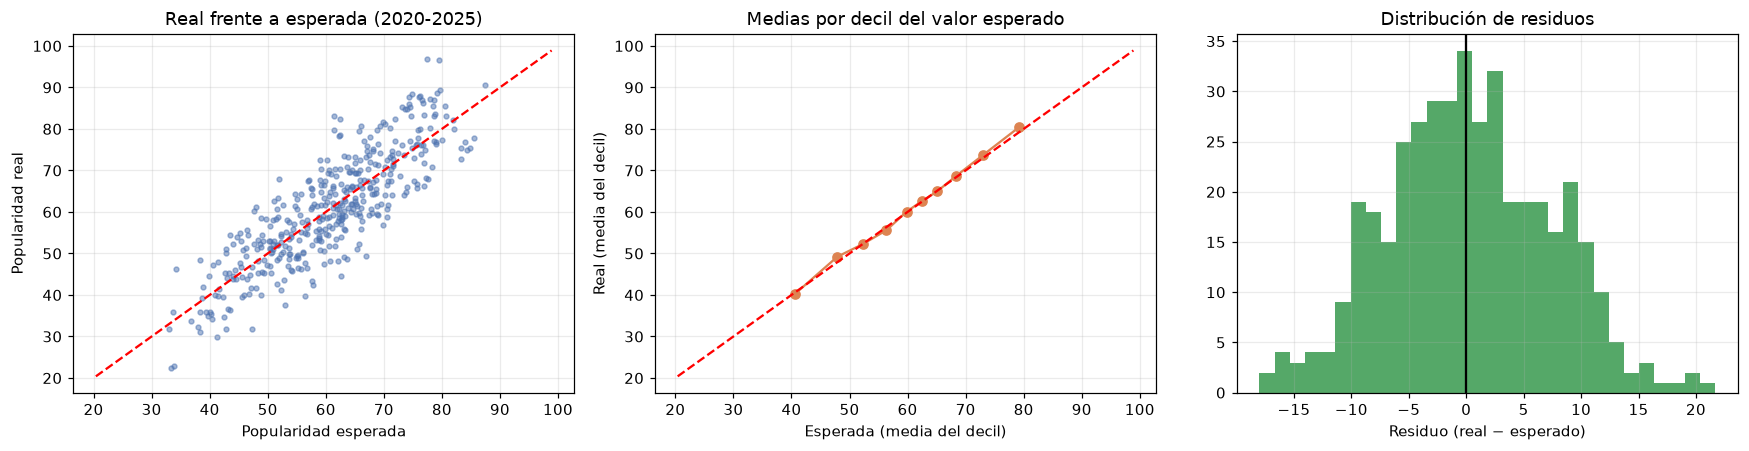

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].scatter(p_sel, yp, s=10, alpha=.5, color="#4C72B0"); lim = [min(p_sel.min(), yp.min()) - 2, max(p_sel.max(), yp.max()) + 2]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Popularidad esperada"); ax[0].set_ylabel("Popularidad real"); ax[0].set_title("Real frente a esperada (2020-2025)")
dec = pd.qcut(p_sel, 10, labels=False, duplicates="drop"); g = pd.DataFrame({"e": p_sel, "r": yp.values, "d": dec}).groupby("d").mean()
ax[1].plot(g.e, g.r, "o-", color="#DD8452"); ax[1].plot(lim, lim, "r--"); ax[1].set_title("Medias por decil del valor esperado"); ax[1].set_xlabel("Esperada (media del decil)"); ax[1].set_ylabel("Real (media del decil)")
ax[2].hist(res, bins=30, color="#55A868"); ax[2].axvline(0, color="k"); ax[2].set_title("Distribución de residuos"); ax[2].set_xlabel("Residuo (real − esperado)")
plt.tight_layout(); plt.savefig("figuras/f3_diagnostico.png"); plt.show()

In [17]:
mayor = por_genero.index[0]; menor = por_genero.index[-1]
sub = por_genero["sesgo"].idxmax(); sob = por_genero["sesgo"].idxmin()
print(f"Segmento donde el modelo falla más: {mayor} (MAE {por_genero.loc[mayor,'MAE']}, sesgo {por_genero.loc[mayor,'sesgo']:+}).")
print(f"Menor error: {menor} (MAE {por_genero.loc[menor,'MAE']}).")
print(f"Mayor subestimación: {sub} (sesgo {por_genero.loc[sub,'sesgo']:+}); mayor sobreestimación: {sob} (sesgo {por_genero.loc[sob,'sesgo']:+}).")

Segmento donde el modelo falla más: urbano (MAE 6.03, sesgo +0.42).
Menor error: rock (MAE 5.14).
Mayor subestimación: pop (sesgo +1.32); mayor sobreestimación: indie (sesgo -0.85).


**Lectura.** Un sesgo global pequeño puede esconder sesgos por segmento: el modelo se equivoca más en unos géneros que en otros y en direcciones contrarias (subestima donde el sesgo es positivo, sobreestima donde es negativo). Los puntos del gráfico siguen la diagonal y las medias por decil son confiables en todo el rango: el modelo sirve **para priorizar un catálogo** aunque sea impreciso para pronosticar una canción individual (una de cada seis queda a más de 10 puntos de lo esperado).

## Fase 5. Importancia y «del error a la decisión»

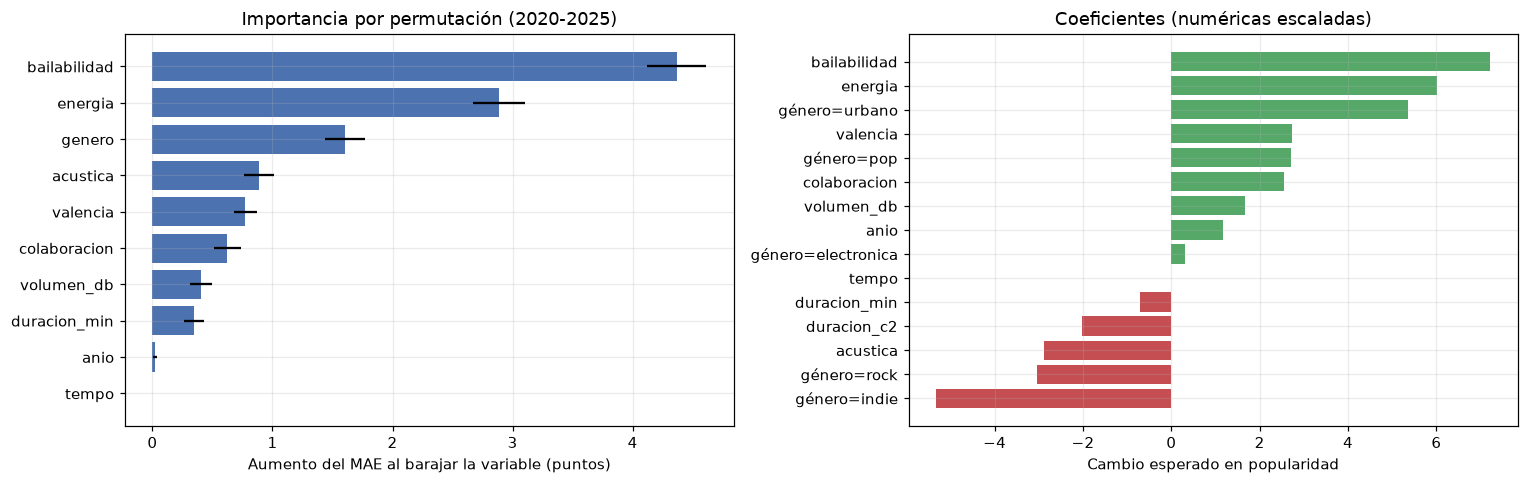

,importancia (aumento de MAE),desv
bailabilidad,4.366,0.248
energia,2.884,0.216
genero,1.603,0.164
acustica,0.889,0.122
valencia,0.775,0.095
colaboracion,0.624,0.112
volumen_db,0.401,0.092
duracion_min,0.344,0.082
anio,0.022,0.015
tempo,-0.000,0.000


In [18]:
from src.variables import derivadas, preprocesamiento
final = make_pipeline(FunctionTransformer(derivadas), preprocesamiento(), LinearRegression()).fit(Xe[COLS_VAL], ye)
assert np.allclose(final.predict(Xp[COLS_VAL]), p_sel), "El pipeline del repositorio debe coincidir con el del notebook"

imp = permutation_importance(final, Xp[COLS_VAL], yp, scoring="neg_mean_absolute_error", n_repeats=30, random_state=SEMILLA)
imp = pd.DataFrame({"importancia (aumento de MAE)": imp.importances_mean, "desv": imp.importances_std}, index=COLS_VAL).sort_values("importancia (aumento de MAE)")
coef = pd.Series(final[-1].coef_, index=final[1].get_feature_names_out()).round(2)
coef.index = [i.replace("cat__genero_", "género=").replace("num__", "") for i in coef.index]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(imp.index, imp.iloc[:, 0], xerr=imp["desv"], color="#4C72B0"); ax[0].set_title("Importancia por permutación (2020-2025)"); ax[0].set_xlabel("Aumento del MAE al barajar la variable (puntos)")
c = coef.sort_values(); ax[1].barh(c.index, c.values, color=["#C44E52" if v < 0 else "#55A868" for v in c.values]); ax[1].set_title("Coeficientes (numéricas escaladas)"); ax[1].set_xlabel("Cambio esperado en popularidad")
plt.tight_layout(); plt.savefig("figuras/f4_importancia.png"); plt.show()
display(imp.sort_values("importancia (aumento de MAE)", ascending=False).round(3))

**Lectura correcta.** La importancia por permutación mide cuánto empeora el error de **este** modelo si se destruye la información de una variable; describe **asociaciones**, no causas. Un coeficiente negativo para un género no indica que el género *cause* menos popularidad: el género también decide listas, radio e inversión.
Las variables de mayor peso son las de audio (bailabilidad y energía) y el género; tempo, duración y año pesan poco.

In [19]:
cortes = []
for corte in (60, 65, 70):
    prom = p_sel > corte
    cortes.append({"Corte sobre popularidad esperada": corte, "Canciones promocionadas": int(prom.sum()),
                   "Promocionadas que alcanzaron 70": int((prom & (yp >= 70)).sum()),
                   "Hits que quedaron sin promoción": int((~prom & (yp >= 70)).sum())})
display(pd.DataFrame(cortes))
print("Canciones de 2020-2025 que alcanzaron 70 puntos:", int((yp >= 70).sum()), "de", len(yp))

,Corte sobre popularidad esperada,Canciones promocionadas,Promocionadas que alcanzaron 70,Hits que quedaron sin promoción
0,60,225,104,2
1,65,148,90,16
2,70,87,68,38


Canciones de 2020-2025 que alcanzaron 70 puntos: 106 de 415


In [20]:
n_hit = int((yp >= 70).sum()); fila65 = cortes[1]
print("CONCLUSIÓN DE NEGOCIO")
_p = print
print = lambda *a, **k: _p(*[es(str(x)) for x in a], **k)
print(f"- El modelo estima la popularidad con un error típico de {tab.loc['Modelo seleccionado','MAE']:.1f} puntos, frente a {tab.loc['Media por género (línea base)','MAE']:.1f} de la línea base.")
print(f"- Sirve para PRIORIZAR el catálogo, no para pronosticar con precisión una canción: {(res.abs()>10).mean():.0%} de las canciones queda a más de 10 puntos.")
print(f"- Con presupuesto para ~150 canciones, el corte 65 promociona {fila65['Canciones promocionadas']} y captura {fila65['Promocionadas que alcanzaron 70']} de los {n_hit} hits; deja {fila65['Hits que quedaron sin promoción']} sin promoción.")
print(f"- Dónde falla más: {mayor}. Subestima {sub} y sobreestima {sob}.")
print("- Límites: datos sintéticos, asociaciones y no causas, un solo periodo de prueba; el corte lo debe fijar quien responde por el presupuesto y pondera el costo de cada error.")
print = _p

CONCLUSIÓN DE NEGOCIO
- El modelo estima la popularidad con un error típico de 5,8 puntos, frente a 10,4 de la línea base.
- Sirve para PRIORIZAR el catálogo, no para pronosticar con precisión una canción: 16% de las canciones queda a más de 10 puntos.
- Con presupuesto para ~150 canciones, el corte 65 promociona 148 y captura 90 de los 106 hits; deja 16 sin promoción.
- Dónde falla más: urbano. Subestima pop y sobreestima indie.
- Límites: datos sintéticos, asociaciones y no causas, un solo periodo de prueba; el corte lo debe fijar quien responde por el presupuesto y pondera el costo de cada error.


## Lectura crítica de un resultado generado por IA (auditoría)

El asistente respondió: *«El modelo de regresión lineal alcanza un R² de 0,98, es decir, una precisión del 98 %. Las variables más importantes son las reproducciones de la primera semana y el indicador de hit. El modelo generaliza bien y está listo para estimar la popularidad de canciones nuevas.»*
Se aplica el protocolo de cinco preguntas, **cambiando una sola cosa por paso** sobre el modelo del asistente (regresión lineal con todas las columnas, partición aleatoria 80/20).

In [21]:
# Paso 1. ¿Corre y da lo mismo? Se ejecuta el código del asistente dos veces con semilla fija (42).
# La cifra exacta puede diferir en milésimas de la citada en clase si la semilla de la partición es otra.
Xa = pd.get_dummies(X_todo, columns=["genero"], drop_first=True)
def asistente(cols_quitar=()):
    Xa_ = Xa.drop(columns=list(cols_quitar))
    a_tr, a_te, b_tr, b_te = train_test_split(Xa_, y, test_size=0.2, random_state=SEMILLA)
    mod = LinearRegression().fit(a_tr, b_tr); p = mod.predict(a_te)
    return mod, a_te, b_te, p
_, _, _, _p1 = asistente(); _, _, bte, p1 = asistente()
r2_1, mae_1 = r2_score(bte, p1), mean_absolute_error(bte, p1)
print(f"Paso 1: R² = {r2_1:.3f} y MAE = {mae_1:.2f} (aleatoria 80/20). Reproducible en dos corridas: {np.allclose(_p1, p1)}")

# Paso 2. Quitar las dos columnas con fuga (misma partición aleatoria).
mod2, a_te2, b_te2, p2 = asistente(LEAK)
r2_2, mae_2 = r2_score(b_te2, p2), mean_absolute_error(b_te2, p2)
print(f"Paso 2: sin fuga, R² = {r2_2:.3f} y MAE = {mae_2:.2f}  (el error sube de {mae_1:.2f} a {mae_2:.2f})")

# Paso 3. Partición temporal (misma corrida: lineal con columnas válidas).
f = reg.set_index("corrida")
r2_3, mae_3 = f.loc["Lineal, columnas válidas", "r2"], f.loc["Lineal, columnas válidas", "mae"]
print(f"Paso 3: temporal 2020-2025, R² = {r2_3:.2f} y MAE = {mae_3:.2f}")

# Paso 4. Línea base con la misma métrica, y error en unidades de negocio.
base_g, base_m = f.loc["Media por género", "mae"], f.loc["Media global", "mae"]
print(f"Paso 4: línea base (media global) MAE = {base_m:.2f}; (media por género) MAE = {base_g:.2f}")

Paso 1: R² = 0.979 y MAE = 1.39 (aleatoria 80/20). Reproducible en dos corridas: True
Paso 2: sin fuga, R² = 0.690 y MAE = 6.16  (el error sube de 1.39 a 6.16)
Paso 3: temporal 2020-2025, R² = 0.70 y MAE = 5.87
Paso 4: línea base (media global) MAE = 11.06; (media por género) MAE = 10.44


In [22]:
# Paso 5. ¿Qué afirma de más? Se verifica cada frase.
# (a) «precisión del 98 %»: R² no es porcentaje de aciertos. Se mide un acierto verdadero: % de canciones dentro de ±5 y ±10 puntos.
a5, a10 = (res.abs() <= 5).mean(), (res.abs() <= 10).mean()     # modelo corregido, prueba temporal
print(f"(a) R² = {r2_1:.3f} es varianza explicada, no un porcentaje de aciertos. Con el modelo corregido (temporal): "
      f"±5 puntos {a5:.0%} de las canciones; ±10 puntos {a10:.0%}")
# (b) «las variables más importantes son las reproducciones y es_hit»: existen antes del lanzamiento? Importancia en su modelo.
mod1, a_te1, _, _ = asistente()
pi = permutation_importance(mod1, a_te1, bte, scoring="neg_mean_absolute_error", n_repeats=20, random_state=SEMILLA)
top = pd.Series(pi.importances_mean, index=a_te1.columns).sort_values(ascending=False)
print("(b) Importancia por permutación en el modelo del asistente (primeras 3):", top.head(3).round(2).to_dict())
# (c) «generaliza bien»: solo probó al azar.
print(f"(c) Con el pasado separado del futuro y sin fuga: R² = {r2_3:.2f}, MAE = {mae_3:.2f}")
# (d) «listo para canciones nuevas»: no comparó con línea base ni dijo el error en puntos.
print(f"(d) Frente a la línea base ({base_g:.2f}), el modelo corregido mejora {1 - mae_3/base_g:.0%}; el del asistente no reportó ni línea base ni error en puntos.")

(a) R² = 0.979 es varianza explicada, no un porcentaje de aciertos. Con el modelo corregido (temporal): ±5 puntos 51% de las canciones; ±10 puntos 84%


(b) Importancia por permutación en el modelo del asistente (primeras 3): {'reproducciones_sem1': 14.46, 'es_hit': 0.59, 'bailabilidad': 0.09}
(c) Con el pasado separado del futuro y sin fuga: R² = 0.70, MAE = 5.87
(d) Frente a la línea base (10.44), el modelo corregido mejora 44%; el del asistente no reportó ni línea base ni error en puntos.


In [23]:
ficha = pd.DataFrame([
    ["«Alcanza un R² de 0,98»", f"Ejecutando su código con semilla fija se obtiene R² = {r2_1:.3f} (≈ 0,98), idéntico en dos corridas", "Reproducible"],
    ["«Una precisión del 98 %»", f"R² es varianza explicada, no porcentaje de aciertos. En el modelo corregido, solo {a5:.0%} de las canciones queda a ±5 puntos y {a10:.0%} a ±10", "Falso"],
    ["«Las variables más importantes son las reproducciones y el indicador de hit»",
     f"Ninguna existe antes del lanzamiento. Sin ellas: R² = {r2_2:.2f} y MAE = {mae_2:.2f} (antes {mae_1:.2f}). Importancia en su modelo: {', '.join(top.head(2).index)}", "Fuga"],
    ["«Generaliza bien»", f"Solo probó al azar. Con canciones de 2020-2025 y sin fuga: R² = {r2_3:.2f} y MAE = {mae_3:.2f}", "Compatible con la evidencia obtenida; la afirmación original no estaba sustentada"],
    ["«Listo para canciones nuevas»", f"No comparó con una línea base ({base_g:.2f}) ni dijo cuánto se equivoca en puntos ({mae_3:.2f})", "Sin sustento"],
], columns=["Afirmación del asistente", "Evidencia de la verificación", "Veredicto"])
ficha["Evidencia de la verificación"] = ficha["Evidencia de la verificación"].map(es)
pd.set_option("display.max_colwidth", 200)
display(ficha)
ficha.to_csv("ficha_auditoria.csv", index=False, encoding="utf-8")

,Afirmación del asistente,Evidencia de la verificación,Veredicto
0,"«Alcanza un R² de 0,98»","Ejecutando su código con semilla fija se obtiene R² = 0,979 (≈ 0,98), idéntico en dos corridas",Reproducible
1,«Una precisión del 98 %»,"R² es varianza explicada, no porcentaje de aciertos. En el modelo corregido, solo 51% de las canciones queda a ±5 puntos y 84% a ±10",Falso
2,«Las variables más importantes son las reproducciones y el indicador de hit»,"Ninguna existe antes del lanzamiento. Sin ellas: R² = 0,69 y MAE = 6,16 (antes 1,39). Importancia en su modelo: reproducciones_sem1, es_hit",Fuga
3,«Generaliza bien»,"Solo probó al azar. Con canciones de 2020-2025 y sin fuga: R² = 0,70 y MAE = 5,87",Compatible con la evidencia obtenida; la afirmación original no estaba sustentada
4,«Listo para canciones nuevas»,"No comparó con una línea base (10,44) ni dijo cuánto se equivoca en puntos (5,87)",Sin sustento


In [24]:
mae_sel = f.loc["Válidas + duración²", "mae"]
memo = [
    f"1. El resultado del asistente (R² = {r2_1:.2f}) se reproduce, pero usa dos columnas que no existen antes del lanzamiento: reproducciones_sem1 y es_hit.",
    f"2. Sin esas columnas el error pasa de {mae_1:.2f} a {mae_2:.2f} puntos; el R² honesto, con partición temporal, es {r2_3:.2f} y no 0,98.",
    f"3. Contra la línea base (media por género, {base_g:.2f} puntos) el modelo corregido y mejorado (lineal + duración², {mae_sel:.2f}) la reduce en {1 - mae_sel/base_g:.0%}: es útil para priorizar, no para pronosticar una canción.",
    "4. «Precisión del 98 %», «generaliza bien» y «listo para canciones nuevas» no estaban sustentadas: R² no es porcentaje de aciertos y no hubo línea base ni prueba temporal.",
    "5. Recomendación: usar el modelo corregido (lineal + duración², MAE ≈ %.2f) con su ficha, y exigir al asistente el momento de la decisión como parte del encargo." % f.loc["Válidas + duración²", "mae"],
]
memo = [es(l) for l in memo]
print("\n".join(memo))
Path("memo_auditoria.txt").write_text("\n".join(memo), encoding="utf-8")

1. El resultado del asistente (R² = 0,98) se reproduce, pero usa dos columnas que no existen antes del lanzamiento: reproducciones_sem1 y es_hit.
2. Sin esas columnas el error pasa de 1,39 a 6,16 puntos; el R² honesto, con partición temporal, es 0,70 y no 0,98.
3. Contra la línea base (media por género, 10,44 puntos) el modelo corregido y mejorado (lineal + duración², 5,75) la reduce en 45%: es útil para priorizar, no para pronosticar una canción.
4. «Precisión del 98 %», «generaliza bien» y «listo para canciones nuevas» no estaban sustentadas: R² no es porcentaje de aciertos y no hubo línea base ni prueba temporal.
5. Recomendación: usar el modelo corregido (lineal + duración², MAE ≈ 5,75) con su ficha, y exigir al asistente el momento de la decisión como parte del encargo.


785

## Cierre: registro, modelo y ficha para el servicio

Se guarda el registro comparativo (todas las corridas, incluidas las descartadas) y se entrena el modelo seleccionado con el código del repositorio (`src/entrenar_regresion.py`), que escribe `models/modelo.pkl` con su ficha. El servicio no cambia: todo lo que necesita está en la ficha.

In [25]:
reg.to_csv("registro_semana9.csv", index=False, encoding="utf-8")
print("registro_semana9.csv:", len(reg), "corridas")

from src.entrenar_regresion import entrenar
modelo = entrenar()
mae_pkl = modelo["ficha"]["desempeno"]["mae"]
assert abs(mae_pkl - f.loc["Válidas + duración²", "mae"]) < 0.01, "El .pkl debe reproducir la corrida seleccionada"
print("\nVerificación: el MAE del .pkl coincide con el del registro ->", mae_pkl)

registro_semana9.csv: 13 corridas
Modelo guardado en /home/claude/repo/models/modelo.pkl (0.00 MB)
{
  "nombre": "lineal + duración² (taller S9, selección por validación temporal interna)",
  "tarea": "regresion",
  "objetivo": "popularidad (0-100) que alcanzará la canción",
  "momento_prediccion": "antes del lanzamiento: la disquera decide cuánto invertir en promoción",
  "variables_entrada": [
    "bailabilidad",
    "energia",
    "valencia",
    "acustica",
    "tempo",
    "duracion_min",
    "volumen_db",
    "anio",
    "colaboracion",
    "genero"
  ],
  "variables_excluidas": {
    "reproducciones_sem1": "ocurre después del lanzamiento: no existe en el momento de decidir",
    "es_hit": "se calcula a partir del objetivo (popularidad >= 70)"
  },
  "entrenamiento": {
    "periodo": "1995-2019",
    "n": 1585
  },
  "prueba": {
    "periodo": "2020-2025",
    "n": 415,
    "tipo": "temporal"
  },
  "linea_base": {
    "descripcion": "media por género (entrenamiento)",
    "mae":